In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Carregar os dados
df = pd.read_excel('carbon_emissions.xlsx')
print(df.head())
print(df.info())

  Characteristic  Emissions in billion metric tons
0          2025¹                             38.11
1           2024                             37.78
2           2023                             37.26
3           2022                             36.72
4           2021                             36.04
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 2 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Characteristic                    86 non-null     object 
 1   Emissions in billion metric tons  86 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.5+ KB
None


In [2]:
# Verificar os últimos registros
print(df.tail(10))
print("\nValores únicos na coluna Characteristic:")
print(df['Characteristic'].unique())

   Characteristic  Emissions in billion metric tons
76           1949                              5.18
77           1948                              5.42
78           1947                              5.15
79           1946                              4.65
80           1945                              4.26
81           1944                              5.12
82           1943                              5.04
83           1942                              4.96
84           1941                              4.97
85           1940                              4.86

Valores únicos na coluna Characteristic:
['2025¹' 2024 2023 2022 2021 2020 2019 2018 2017 2016 2015 2014 2013 2012
 2011 2010 2009 2008 2007 2006 2005 2004 2003 2002 2001 2000 1999 1998
 1997 1996 1995 1994 1993 1992 1991 1990 1989 1988 1987 1986 1985 1984
 1983 1982 1981 1980 1979 1978 1977 1976 1975 1974 1973 1972 1971 1970
 1969 1968 1967 1966 1965 1964 1963 1962 1961 1960 1959 1958 1957 1956
 1955 1954 1953 1952 1951 19

In [3]:
# Limpar e preparar os dados
df_clean = df.copy()

# Remover caracteres especiais e converter ano para inteiro
df_clean['Year'] = df_clean['Characteristic'].astype(str).str.replace('¹', '').astype(int)

# Converter bilhões para milhões (multiplicar por 1000)
df_clean['Emissions_millions'] = df_clean['Emissions in billion metric tons'] * 1000

# Ordenar por ano
df_clean = df_clean.sort_values('Year')

print(df_clean.head())
print(f"\nPeríodo: {df_clean['Year'].min()} - {df_clean['Year'].max()}")

   Characteristic  Emissions in billion metric tons  Year  Emissions_millions
85           1940                              4.86  1940              4860.0
84           1941                              4.97  1941              4970.0
83           1942                              4.96  1942              4960.0
82           1943                              5.04  1943              5040.0
81           1944                              5.12  1944              5120.0

Período: 1940 - 2025


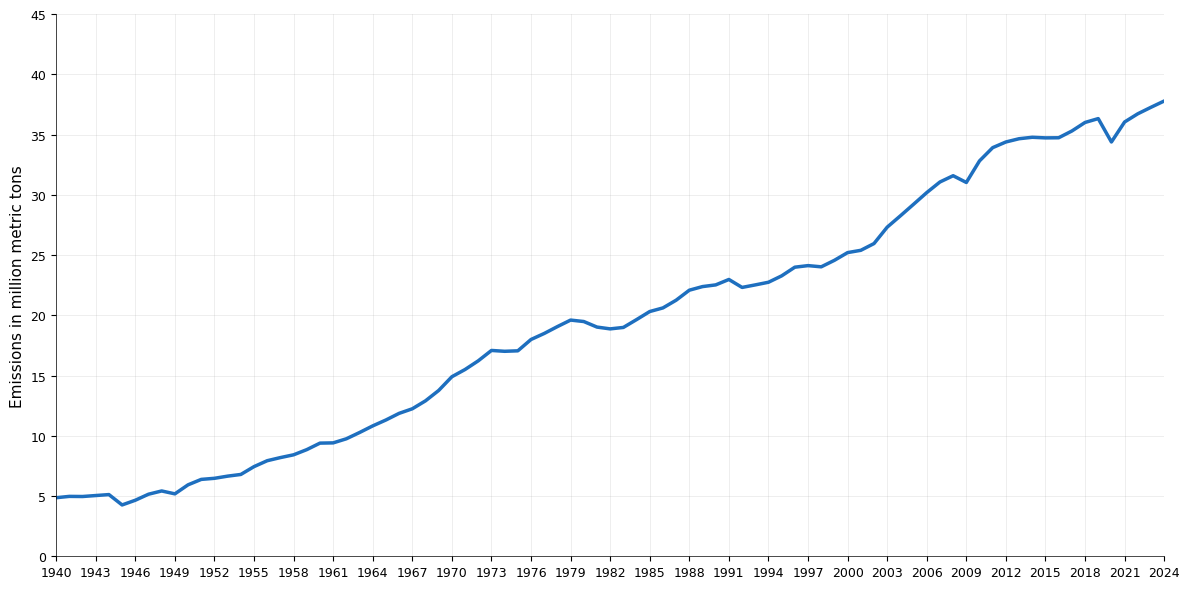

Gráfico criado com sucesso!
Emissões em 1940: 4860.00 milhões de toneladas
Emissões em 2024: 37780.00 milhões de toneladas
Crescimento: 677.4%


In [4]:
# Criar gráfico inspirado na figura anexa
plt.figure(figsize=(12, 6))

# Plotar a linha
plt.plot(df_clean['Year'], df_clean['Emissions_millions'], 
         color='#1E6FBF', linewidth=2.5, solid_capstyle='round')

# Configurar eixos e grid
plt.xlabel('', fontsize=11)
plt.ylabel('Emissions in million metric tons', fontsize=11)
plt.grid(True, axis='y', alpha=0.3, linestyle='-', linewidth=0.5)
plt.grid(True, axis='x', alpha=0.3, linestyle='-', linewidth=0.5)

# Configurar limites dos eixos
plt.ylim(0, 45000)
plt.xlim(1940, 2024)

# Configurar os ticks do eixo x
years_ticks = list(range(1940, 2025, 3))
plt.xticks(years_ticks, rotation=0, fontsize=9)

# Configurar os ticks do eixo y
y_ticks = list(range(0, 50, 5))
plt.yticks([y * 1000 for y in y_ticks], [str(y) for y in y_ticks], fontsize=9)

# Remover as bordas superior e direita
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.5)
ax.spines['bottom'].set_linewidth(0.5)

# Ajustar layout
plt.tight_layout()

# Salvar e mostrar
plt.savefig('carbon_emissions_graph.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico criado com sucesso!")
print(f"Emissões em 1940: {df_clean[df_clean['Year']==1940]['Emissions_millions'].values[0]:.2f} milhões de toneladas")
print(f"Emissões em 2024: {df_clean[df_clean['Year']==2024]['Emissions_millions'].values[0]:.2f} milhões de toneladas")
print(f"Crescimento: {(df_clean[df_clean['Year']==2024]['Emissions_millions'].values[0] / df_clean[df_clean['Year']==1940]['Emissions_millions'].values[0] - 1) * 100:.1f}%")

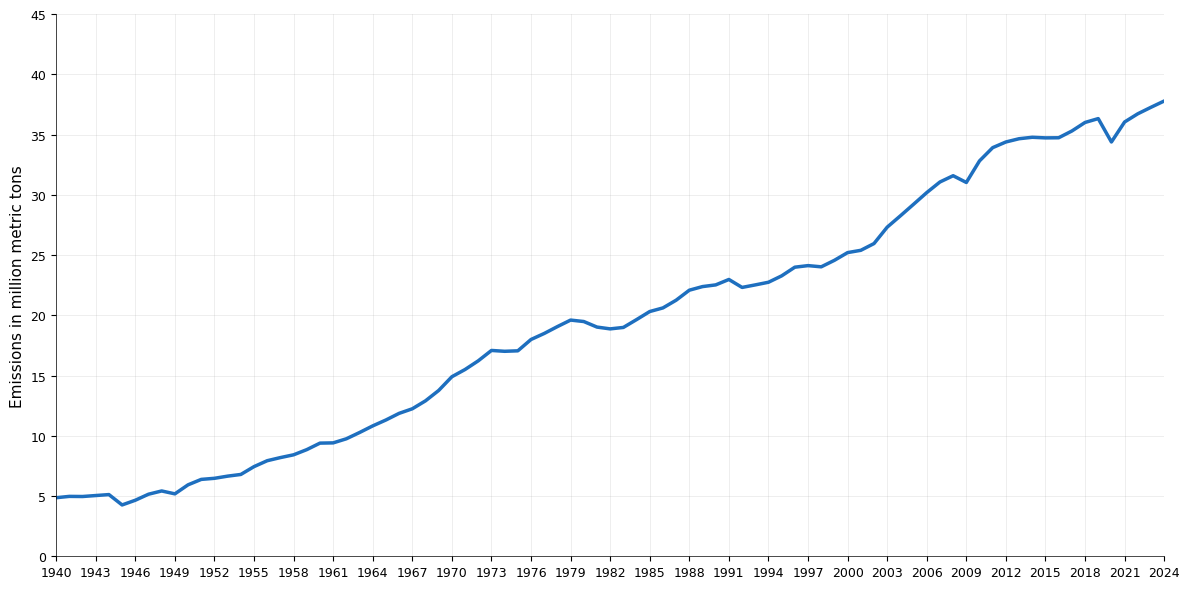

✓ Gráficos salvos em 3 formatos:
  • carbon_emissions_graph.pdf (RECOMENDADO para LaTeX)
  • carbon_emissions_graph.svg (vetorial alternativo)
  • carbon_emissions_graph.png (raster)

Para usar no LaTeX:
\usepackage{graphicx}
\includegraphics[width=0.8\textwidth]{carbon_emissions_graph.pdf}


In [5]:
# Criar versão otimizada para LaTeX (PDF vetorial)
plt.figure(figsize=(12, 6))

# Plotar a linha
plt.plot(df_clean['Year'], df_clean['Emissions_millions'], 
         color='#1E6FBF', linewidth=2.5, solid_capstyle='round')

# Configurar eixos e grid
plt.xlabel('', fontsize=11)
plt.ylabel('Emissions in million metric tons', fontsize=11)
plt.grid(True, axis='y', alpha=0.3, linestyle='-', linewidth=0.5)
plt.grid(True, axis='x', alpha=0.3, linestyle='-', linewidth=0.5)

# Configurar limites dos eixos
plt.ylim(0, 45000)
plt.xlim(1940, 2024)

# Configurar os ticks do eixo x
years_ticks = list(range(1940, 2025, 3))
plt.xticks(years_ticks, rotation=0, fontsize=9)

# Configurar os ticks do eixo y
y_ticks = list(range(0, 50, 5))
plt.yticks([y * 1000 for y in y_ticks], [str(y) for y in y_ticks], fontsize=9)

# Remover as bordas superior e direita
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.5)
ax.spines['bottom'].set_linewidth(0.5)

# Ajustar layout
plt.tight_layout()

# Salvar em múltiplos formatos para LaTeX
plt.savefig('carbon_emissions_graph.pdf', dpi=300, bbox_inches='tight', backend='pdf')  # Vetorial - RECOMENDADO para LaTeX
plt.savefig('carbon_emissions_graph.svg', dpi=300, bbox_inches='tight')  # Vetorial alternativo
plt.savefig('carbon_emissions_graph.png', dpi=300, bbox_inches='tight')  # Raster

plt.show()

print("✓ Gráficos salvos em 3 formatos:")
print("  • carbon_emissions_graph.pdf (RECOMENDADO para LaTeX)")
print("  • carbon_emissions_graph.svg (vetorial alternativo)")
print("  • carbon_emissions_graph.png (raster)")
print("\nPara usar no LaTeX:")
print("\\usepackage{graphicx}")
print("\\includegraphics[width=0.8\\textwidth]{carbon_emissions_graph.pdf}")